# 03. Model B: Random Forest

**Owner:** Member B (Random Forest)
**Step 10:** tune the Random Forest on the training years, choose its decision threshold, and check it once on the validation years.

**Inputs.** The agreed preprocessing from step 8, `make_selected_preprocessor()`: the shared pipeline followed by L1 selection, which keeps 9 of the 42 encoded inputs.

**The bar to beat** (from `03_baselines.ipynb`): the persistence score, which ranks weeks by this week's cases divided by the district's outbreak threshold. It reaches PR-AUC **0.687** across the 2016 to 2020 cross-validation years and **0.554** on 2021 to 2022, without any learning.

**Rules this notebook follows**

- Hyperparameters are chosen on the five expanding-window cross-validation years (2016 to 2020) only.
- The decision threshold is chosen on the same cross-validation predictions.
- The validation years 2021 to 2022 are used once, at the end, as a check. Nothing is changed after seeing them.
- The test years 2023 to 2025 stay sealed until step 11.

## 1. How a Random Forest works, and why it suits this problem

*Notes for the report's algorithm section (criterion 4).*

**Decision tree.** A tree splits the training weeks again and again on one input at a time, for example `cases_rel_threshold` above 0.8. At each node it picks the split that most reduces Gini impurity, the CART criterion from lecture 5. Every path from the root to a leaf is an IF-THEN rule, and the share of outbreak weeks in a leaf is its predicted probability. A single tree grown to full depth fits the training years too closely: low bias, but high variance.

**Random Forest: bagging plus random feature selection.** Many trees are trained independently, each on a bootstrap sample of the training weeks drawn with replacement. At every split, a tree may only choose from a random subset of the inputs (`max_features`). This makes the trees differ from one another, so combining them cancels much of their individual error: averaging reduces variance without adding much bias. scikit-learn combines the trees by averaging their leaf probabilities, a soft version of the majority vote.

**Why it suits this problem**

- An outbreak is defined by cases crossing a threshold, and risk rises sharply rather than in a straight line as cases climb. Splits on case levels match that shape directly.
- Trees find interactions without being told, for example high cases now together with a rising trend, or rainfall that matters only when cases are already elevated.
- No scaling or distributional assumptions are needed, so skewed counts and extreme epidemic weeks do not distort the fit.
- Feature importance shows which inputs the model relies on.

**Weaknesses to keep in mind**

- The probabilities are not calibrated, so the decision threshold has to be chosen, not assumed to be 0.5.
- Trees cannot extrapolate beyond the range of the training data.
- A forest of hundreds of trees is far harder to read than a single tree or a Logistic Regression.

**Hyperparameters tuned here.** The first two are pre-pruning controls (lecture 5); the search itself is the grid search from lecture 7.

| Hyperparameter | What it controls | Values tried |
|---|---|---|
| `max_depth` | How deep each tree may grow | 6, 10, 16, no limit |
| `min_samples_leaf` | Fewest training weeks allowed in a leaf | 1, 5, 20, 50 |
| `max_features` | Inputs considered at each split | sqrt (3 of 9), 0.6 (5 of 9), all 9 (plain bagging) |
| `class_weight` | Whether outbreak weeks are up-weighted | none, balanced within each bootstrap sample |

`n_estimators`, the number of trees, is fixed at 300. Adding trees only makes the average less noisy and cannot cause overfitting, so it is checked rather than tuned (section 2.2).

In [1]:
import json
import sys
import time
from pathlib import Path

# Make the project root importable so the shared `src` modules work from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

from src import config, viz
from src.evaluation import (
    METRIC_NAMES, choose_threshold, classification_metrics, cross_validate, out_of_fold_scores,
    reference_models,
)
from src.preprocessing import (
    CV_VALIDATION_YEARS, MODEL_FEATURES, build_model_frame, expanding_year_folds,
    make_selected_preprocessor, selected_inputs,
)

viz.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [2]:
frame = build_model_frame()
train_frame = frame[frame["split"] == "train"].reset_index(drop=True)
val_frame = frame[frame["split"] == "val"].reset_index(drop=True)
X, y = train_frame[MODEL_FEATURES], train_frame["target"]
X_val, y_val = val_frame[MODEL_FEATURES], val_frame["target"]
folds = expanding_year_folds(train_frame)
YEARS = [str(year) for year in CV_VALIDATION_YEARS]

# The bar from step 9: PR-AUC of the persistence score in each cross-validation year.
persistence_score_cv = pd.Series(
    [average_precision_score(y.iloc[va], train_frame["cases_rel_threshold"].iloc[va]) for _, va in folds],
    index=YEARS,
)
PERSISTENCE_SCORE_CV = persistence_score_cv.mean()
print(f"Training rows: {len(X):,}   Validation rows (2021-2022): {len(X_val):,}")
print(f"Persistence score, mean PR-AUC across 2016-2020: {PERSISTENCE_SCORE_CV:.3f}")

Training rows: 18,200   Validation rows (2021-2022): 2,575
Persistence score, mean PR-AUC across 2016-2020: 0.687


## 2. Tuning with grid search

Every combination in the grid is scored on the same five expanding-window folds used throughout the project: for each validation year, the forest is trained on all earlier years and scored on that year by PR-AUC. The combination with the highest mean PR-AUC across the five years wins.

The grid has 4 × 4 × 3 × 2 = 96 combinations, so the search fits 480 forests. It takes a few minutes on a laptop.

In [3]:
N_TREES = 300
GRID = {
    "clf__max_depth": [6, 10, 16, None],
    "clf__min_samples_leaf": [1, 5, 20, 50],
    "clf__max_features": ["sqrt", 0.6, 1.0],
    "clf__class_weight": [None, "balanced_subsample"],
}
pipeline = Pipeline([
    ("prep", make_selected_preprocessor()),
    ("clf", RandomForestClassifier(n_estimators=N_TREES, random_state=config.RANDOM_SEED, n_jobs=1)),
])
search = GridSearchCV(pipeline, GRID, cv=folds, scoring="average_precision", n_jobs=-1, refit=True)

start = time.time()
search.fit(X, y)
print(f"Fitted {len(search.cv_results_['params']) * len(folds)} forests in {(time.time() - start) / 60:.1f} minutes.")
print("Best settings:", {k.replace("clf__", ""): v for k, v in search.best_params_.items()})
print(f"Best mean PR-AUC across 2016-2020: {search.best_score_:.3f}")

Fitted 480 forests in 8.0 minutes.
Best settings: {'class_weight': None, 'max_depth': 6, 'max_features': 1.0, 'min_samples_leaf': 50}
Best mean PR-AUC across 2016-2020: 0.711


In [4]:
PARAM_LABELS = {
    "clf__max_depth": "max_depth", "clf__min_samples_leaf": "min_samples_leaf",
    "clf__max_features": "max_features", "clf__class_weight": "class_weight",
}
cv_table = pd.DataFrame(search.cv_results_)
# Labels come from the raw parameter dicts, so None (no depth limit, no class weighting) stays visible.
tuning = pd.DataFrame({label: [str(p[param]) for p in search.cv_results_["params"]]
                       for param, label in PARAM_LABELS.items()})
tuning["mean PR-AUC"] = cv_table["mean_test_score"]
tuning["std across years"] = cv_table["std_test_score"]
for i, year in enumerate(YEARS):
    tuning[year] = cv_table[f"split{i}_test_score"]
tuning["rank"] = cv_table["rank_test_score"]
tuning = tuning.iloc[np.argsort(cv_table["rank_test_score"].to_numpy(), kind="stable")].reset_index(drop=True)
assert search.best_score_ == tuning.loc[0, "mean PR-AUC"]  # row 0 is the winning combination
tuning.head(10)

,max_depth,min_samples_leaf,max_features,class_weight,mean PR-AUC,std across years,2016,2017,2018,2019,2020,rank
0,6,50,1.0,None,0.711,0.234,0.302,0.893,0.602,0.927,0.834,1
1,None,50,1.0,None,0.711,0.236,0.298,0.893,0.603,0.927,0.835,2
2,16,50,1.0,None,0.711,0.236,0.298,0.893,0.603,0.927,0.835,3
3,6,5,0.6,None,0.711,0.240,0.283,0.889,0.613,0.923,0.847,4
4,16,20,0.6,None,0.711,0.240,0.285,0.888,0.610,0.926,0.846,5
5,None,20,0.6,None,0.711,0.240,0.286,0.888,0.608,0.926,0.847,6
6,10,50,1.0,None,0.711,0.236,0.298,0.893,0.603,0.927,0.834,7
7,10,20,0.6,None,0.711,0.241,0.282,0.890,0.611,0.926,0.845,8
8,6,1,0.6,None,0.711,0.237,0.290,0.883,0.610,0.924,0.846,9
9,10,5,sqrt,None,0.711,0.237,0.287,0.878,0.614,0.921,0.852,10


### 2.1 What each setting does

For each value of each hyperparameter, the chart shows the best mean PR-AUC reachable with that value, whatever the other settings. A flat panel means the setting hardly matters; a steep one means it does. The dashed line is the persistence score.

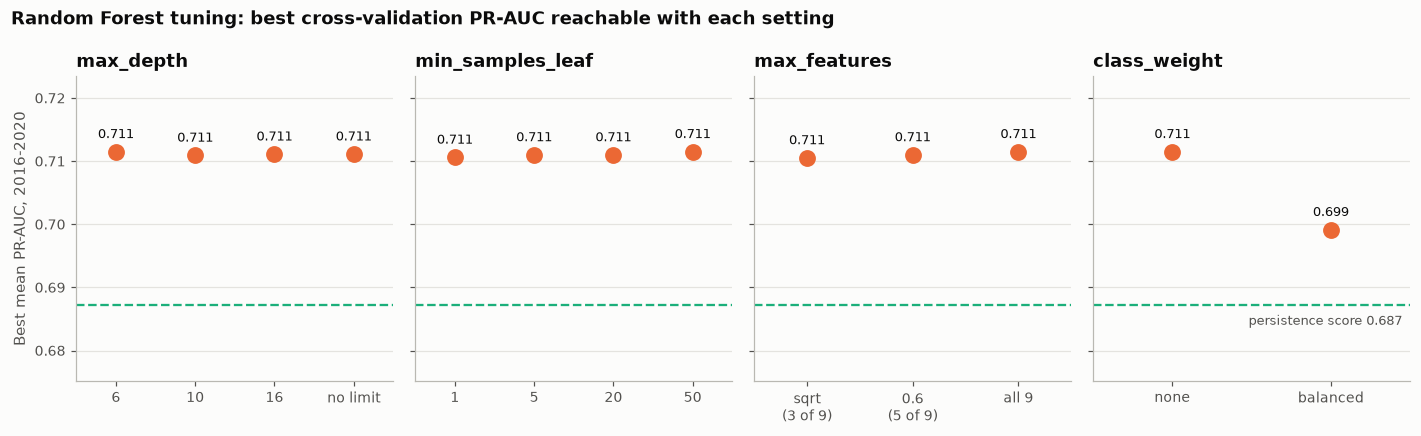

In [5]:
DISPLAY = {
    "max_depth": {"6": "6", "10": "10", "16": "16", "None": "no limit"},
    "min_samples_leaf": {"1": "1", "5": "5", "20": "20", "50": "50"},
    "max_features": {"sqrt": "sqrt\n(3 of 9)", "0.6": "0.6\n(5 of 9)", "1.0": "all 9"},
    "class_weight": {"None": "none", "balanced_subsample": "balanced"},
}
best_by_value = {label: tuning.groupby(label)["mean PR-AUC"].max().reindex(list(DISPLAY[label]))
                 for label in DISPLAY}

fig, axes = plt.subplots(1, 4, figsize=(13, 4), sharey=True)
for ax, (label, best) in zip(axes, best_by_value.items()):
    positions = np.arange(len(best))
    ax.plot(positions, best.values, "o", color=viz.ORANGE, markersize=10, zorder=3)
    for pos, value in zip(positions, best.values):
        ax.annotate(f"{value:.3f}", (pos, value), textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=8.5, color=viz.TEXT)
    ax.axhline(PERSISTENCE_SCORE_CV, color=viz.AQUA, linestyle="--", linewidth=1.5, zorder=1)
    ax.set_xticks(positions, [DISPLAY[label][v] for v in best.index])
    ax.set_xlim(-0.5, len(best) - 0.5)
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Best mean PR-AUC, 2016-2020")
axes[-1].annotate(f"persistence score {PERSISTENCE_SCORE_CV:.3f}", (len(best_by_value["class_weight"]) - 0.55, PERSISTENCE_SCORE_CV),
                  textcoords="offset points", xytext=(0, -13), ha="right", fontsize=8.5, color=viz.TEXT_MUTED)
low = min(b.min() for b in best_by_value.values())
axes[0].set_ylim(min(low, PERSISTENCE_SCORE_CV) - 0.012, max(b.max() for b in best_by_value.values()) + 0.012)
fig.suptitle("Random Forest tuning: best cross-validation PR-AUC reachable with each setting",
             x=0.01, ha="left", fontweight="bold", color=viz.TEXT)
fig.tight_layout()
viz.save(fig, "rf_01_tuning")
plt.show()

**Finding.** The search finds a broad plateau rather than a sharp peak: the ten best settings are all within 0.001 of each other. Three patterns stand out.

- **Class weighting is the setting that matters most, and it hurts.** The best score without weighting is 0.711; with balanced weights it is 0.699. For fully grown trees the gap is wider: 0.702 without weighting against 0.670 with it. Weighting each outbreak week about eleven times more heavily makes the trees chase individual outbreak weeks, which adds noise to the ranking. PR-AUC rewards a good ranking, and the class imbalance is handled later by the decision threshold instead.
- **Restraining tree growth adds a little more.** Every one of the top ten limits tree growth, through a depth of at most 10, leaves of at least 20 weeks, or both. The winner sits at the most restrained corner, depth 6 with at least 50 weeks in every leaf, about 0.01 above fully grown trees. This is the overfitting point from lecture 5, on a small scale.
- **Random feature selection neither helps nor hurts.** The winner considers all 9 inputs at every split, which makes it bagged trees rather than a random forest in the strict sense of lecture 5. Settings with 3 or 5 inputs per split come within 0.001 with different partners. With only 9 inputs and one of them dominant (section 7), hiding the strongest input from some splits costs about as much as the extra variety between trees gains.

### 2.2 Is 300 trees enough?

The best settings are refitted with 100, 300 and 600 trees on the same folds. If 300 and 600 score the same, more trees would only cost time.

In [6]:
best_clf = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}
tree_check = {}
for n_trees in (100, 300, 600):
    forest = RandomForestClassifier(n_estimators=n_trees, random_state=config.RANDOM_SEED, n_jobs=-1, **best_clf)
    scores = cross_validate(make_selected_preprocessor, X, y, folds, models={"Random Forest": forest})
    tree_check[n_trees] = scores["pr_auc"].mean()
tree_check = pd.Series(tree_check, name="mean PR-AUC, 2016-2020").rename_axis("n_estimators")
tree_check.to_frame()

,"mean PR-AUC, 2016-2020"
n_estimators,
100,0.704
300,0.711
600,0.714


**Finding.** Going from 100 to 300 trees adds 0.007; doubling again to 600 adds only 0.003, about the size of the differences across the top of the grid. The forest is close to converged at 300 trees, and 600 would double the run time, so 300 is kept.

## 3. Tuned forest against the bar, year by year

The untuned forest is the step 8 reference model (default settings with balanced class weights) on the same 9 inputs.

In [7]:
untuned = cross_validate(make_selected_preprocessor, X, y, folds,
                         models={"Random Forest": reference_models()["Random Forest"]})
by_year = pd.DataFrame({
    "Persistence score": persistence_score_cv,
    "Random Forest, untuned (step 8)": untuned["pr_auc"].to_numpy(),
    "Random Forest, tuned": tuning.loc[0, YEARS].astype(float).to_numpy(),
}, index=YEARS).T
by_year["mean"] = by_year.mean(axis=1)
by_year.loc["Tuned minus persistence score"] = by_year.loc["Random Forest, tuned"] - by_year.loc["Persistence score"]
by_year

,2016,2017,2018,2019,2020,mean
Persistence score,0.291,0.890,0.544,0.916,0.796,0.687
"Random Forest, untuned (step 8)",0.238,0.775,0.593,0.895,0.833,0.667
"Random Forest, tuned",0.302,0.893,0.602,0.927,0.834,0.711
Tuned minus persistence score,0.011,0.003,0.058,0.012,0.038,0.024


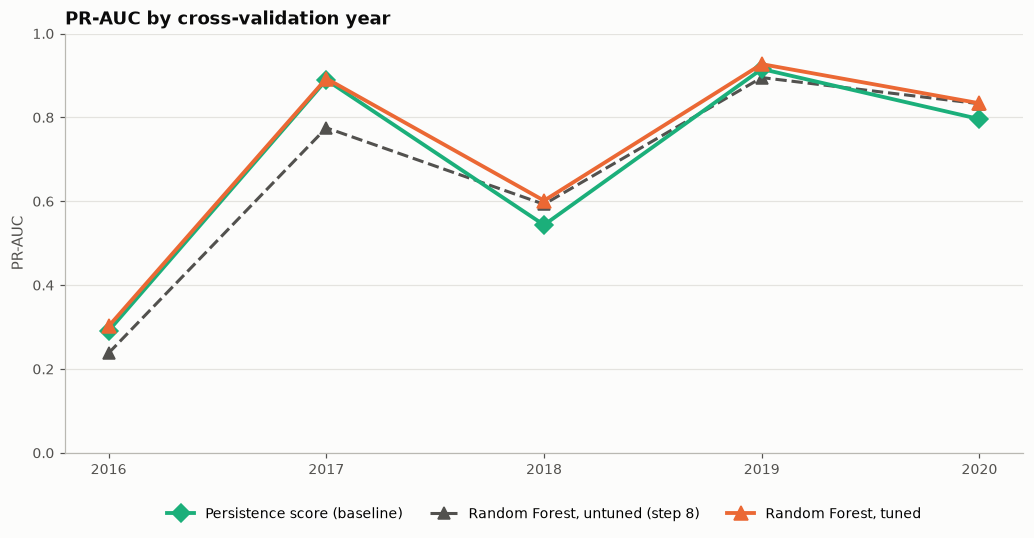

In [8]:
x = np.arange(len(YEARS))
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.plot(x, by_year.loc["Persistence score", YEARS], color=viz.AQUA, linewidth=2.5, marker="D", markersize=8,
        label="Persistence score (baseline)", zorder=3)
ax.plot(x, by_year.loc["Random Forest, untuned (step 8)", YEARS], color=viz.TEXT_MUTED, linestyle="--",
        linewidth=2, marker="^", markersize=8, label="Random Forest, untuned (step 8)", zorder=2)
ax.plot(x, by_year.loc["Random Forest, tuned", YEARS], color=viz.ORANGE, linewidth=2.5, marker="^",
        markersize=9, label="Random Forest, tuned", zorder=4)
ax.set_xticks(x, YEARS)
ax.set_ylim(0, 1)
ax.set_ylabel("PR-AUC")
ax.set_title("PR-AUC by cross-validation year")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fig.tight_layout()
viz.save(fig, "rf_02_cv_by_year")
plt.show()

**Finding.** The tuned forest beats the persistence score in all five years, by margins from 0.003 (2017) to 0.058 (2018), and by 0.024 on average (0.711 against 0.687). Tuning adds 0.045 over the untuned step 8 forest, most of it in 2017 (+0.118), where the fully grown, class-weighted trees did worst. The largest gains over the persistence score come in 2018 and 2020.

## 4. Choosing the decision threshold

PR-AUC judges the ranking. To issue an actual warning, the forest needs a cut-off: predict an outbreak when its score is at or above the threshold. The forest's scores are not calibrated probabilities, so 0.5 has no special meaning.

The threshold is chosen on the cross-validation predictions: for each year 2016 to 2020, scores from a forest trained only on earlier years (`out_of_fold_scores`). The chosen threshold maximises F1 averaged across the five years (`choose_threshold`), so each year counts equally. Pooling all weeks instead would let 2017, which holds about half of all outbreak weeks, decide the threshold by itself.

In [9]:
final_pipeline = clone(search.best_estimator_).set_params(clf__n_jobs=-1)
oof = out_of_fold_scores(final_pipeline, X, y, folds)
oof["target"] = y.iloc[oof.index].to_numpy()
oof["outbreak_now"] = train_frame["outbreak_now"].iloc[oof.index].to_numpy()
oof["persistence score"] = train_frame["cases_rel_threshold"].iloc[oof.index].to_numpy()

# The out-of-fold scores must reproduce the grid search's fold scores exactly.
oof_pr_auc = [average_precision_score(g["target"], g["score"]) for _, g in oof.groupby("fold")]
assert np.allclose(oof_pr_auc, tuning.loc[0, YEARS].astype(float).to_numpy())

THRESHOLD = choose_threshold(oof["target"], oof["score"], groups=oof["fold"])
print(f"Chosen threshold: {THRESHOLD:.3f}")

Chosen threshold: 0.323


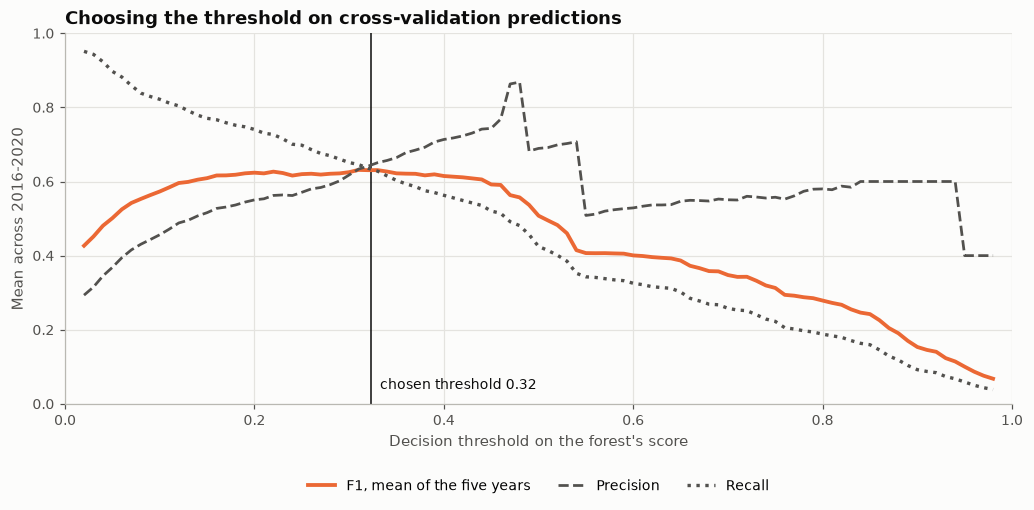

In [10]:
grid = np.round(np.arange(0.02, 0.99, 0.01), 2)
curves = {name: [] for name in ("precision", "recall", "F1")}
for t in grid:
    per_year = [classification_metrics(g["target"], g["score"], t) for _, g in oof.groupby("fold")]
    for name in curves:
        curves[name].append(np.mean([m[name] for m in per_year]))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(grid, curves["F1"], color=viz.ORANGE, linewidth=2.5, label="F1, mean of the five years")
ax.plot(grid, curves["precision"], color=viz.TEXT_MUTED, linestyle="--", linewidth=1.8, label="Precision")
ax.plot(grid, curves["recall"], color=viz.TEXT_MUTED, linestyle=":", linewidth=2.2, label="Recall")
ax.axvline(THRESHOLD, color=viz.TEXT, linewidth=1, zorder=1)
ax.annotate(f"chosen threshold {THRESHOLD:.2f}", (THRESHOLD, 0.04), textcoords="offset points", xytext=(6, 0),
            fontsize=9, color=viz.TEXT)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Decision threshold on the forest's score")
ax.set_ylabel("Mean across 2016-2020")
ax.set_title("Choosing the threshold on cross-validation predictions")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
fig.tight_layout()
viz.save(fig, "rf_03_threshold")
plt.show()

In [11]:
SUMMARY_METRICS = ["PR-AUC", "ROC-AUC", "precision", "recall", "F1", "MCC", "accuracy"]
rows = []
for year, g in zip(YEARS, (g for _, g in oof.groupby("fold"))):
    rows.append({"model": "Random Forest, tuned", "year": year, **classification_metrics(g["target"], g["score"], THRESHOLD)})
    rows.append({"model": "Persistence", "year": year, **classification_metrics(g["target"], g["outbreak_now"], 0.5)})
cv_metrics = pd.DataFrame(rows)
cv_metrics_mean = cv_metrics.groupby("model", sort=False)[SUMMARY_METRICS].mean()
cv_metrics_mean

,PR-AUC,ROC-AUC,precision,recall,F1,MCC,accuracy
model,,,,,,,
"Random Forest, tuned",0.711,0.912,0.645,0.635,0.632,0.569,0.906
Persistence,0.496,0.796,0.624,0.664,0.638,0.568,0.906


**Finding.** The chosen threshold is 0.32, well below 0.5, which confirms that the forest's scores are not calibrated probabilities. At this cut-off, the forest's yes or no warnings across 2016 to 2020 are almost exactly as good as those of persistence: precision 0.645 against 0.624, recall 0.635 against 0.664, F1 0.632 against 0.638 and MCC 0.569 against 0.568.

The forest's advantage lies in its ranking (PR-AUC 0.711 against 0.496 for the 0 or 1 persistence rule). That matters as soon as the cut-off is moved, for example to catch more outbreaks at the cost of more false alarms, which persistence cannot do. Above a threshold of about 0.45 the precision curve becomes erratic, because in some years the forest then issues almost no warnings.

## 5. Where the gain comes from: onsets and continuing outbreaks

Every week falls into one of two situations, and they pose different questions:

- **No outbreak now.** Will one start within two weeks? These onset weeks are where an early warning is most useful, and the hardest to predict. Plain persistence misses all of them by definition.
- **Outbreak now.** Will it still be running in two weeks, or will it have ended?

The table scores the forest and the persistence score separately within each situation, in each cross-validation year. In the onset columns, chance level is the onset rate.

In [12]:
rows = []
for year, g in zip(YEARS, (g for _, g in oof.groupby("fold"))):
    calm, active = g[g["outbreak_now"] == 0], g[g["outbreak_now"] == 1]
    rows.append({
        "year": year,
        "onsets": int(calm["target"].sum()),
        "onset rate": calm["target"].mean(),
        "onsets: RF PR-AUC": average_precision_score(calm["target"], calm["score"]),
        "onsets: persistence score PR-AUC": average_precision_score(calm["target"], calm["persistence score"]),
        "onsets: RF recall at threshold": classification_metrics(calm["target"], calm["score"], THRESHOLD)["recall"],
        "continuing: RF PR-AUC": average_precision_score(active["target"], active["score"]),
        "continuing: persistence score PR-AUC": average_precision_score(active["target"], active["persistence score"]),
    })
onsets = pd.DataFrame(rows).set_index("year")
onsets.loc["mean"] = onsets.mean()
onsets.loc["mean", "onsets"] = np.nan
onsets["onsets"] = onsets["onsets"].astype("Int64")
onsets

,onsets,onset rate,onsets: RF PR-AUC,onsets: persistence score PR-AUC,onsets: RF recall at threshold,continuing: RF PR-AUC,continuing: persistence score PR-AUC
year,,,,,,,
2016,43,0.034,0.170,0.185,0.000,0.594,0.581
2017,139,0.217,0.398,0.396,0.000,0.943,0.940
2018,42,0.036,0.097,0.119,0.071,0.843,0.743
2019,72,0.074,0.411,0.362,0.222,0.975,0.968
2020,10,0.009,0.090,0.094,0.000,0.902,0.858
mean,<NA>,0.074,0.233,0.231,0.059,0.852,0.818


**Finding.** The forest's gain comes almost entirely from weeks already in outbreak. There it judges better whether the outbreak will still be running in two weeks (mean PR-AUC 0.852 against 0.818), with the largest margin in 2018 (0.843 against 0.743).

At onsets it is level with the persistence score (0.233 against 0.231). Both rank onsets about three times better than chance (0.074), but at the chosen threshold the forest flags only 6% of them. In short, the forest is better at judging whether an outbreak will persist than at seeing a new one coming. Seeing onsets earlier would need information the current inputs carry poorly, such as outbreaks in neighbouring districts.

## 6. One check on the validation years, 2021 to 2022

The tuned forest is trained on all training years (2007 to 2020) with the chosen settings, then scored once on 2021 to 2022 at the threshold chosen above. The untuned step 8 forest and both persistence baselines are shown for reference. Nothing in this notebook is changed after this point.

In [13]:
final_model = search.best_estimator_  # refitted on all of 2007-2020 by GridSearchCV
untuned_model = Pipeline([("prep", make_selected_preprocessor()),
                          ("clf", reference_models()["Random Forest"])]).fit(X, y)

validation = pd.DataFrame({
    "Random Forest, tuned": classification_metrics(y_val, final_model.predict_proba(X_val)[:, 1], THRESHOLD),
    "Random Forest, untuned (step 8)": classification_metrics(y_val, untuned_model.predict_proba(X_val)[:, 1], 0.5),
    "Persistence score": classification_metrics(y_val, val_frame["cases_rel_threshold"], 1.0),
    "Persistence": classification_metrics(y_val, val_frame["outbreak_now"], 0.5),
}).T[METRIC_NAMES]

calm = (val_frame["outbreak_now"] == 0).to_numpy()
validation["onset PR-AUC"] = [
    average_precision_score(y_val[calm], final_model.predict_proba(X_val[calm])[:, 1]),
    average_precision_score(y_val[calm], untuned_model.predict_proba(X_val[calm])[:, 1]),
    average_precision_score(y_val[calm], val_frame.loc[calm, "cases_rel_threshold"]),
    float(y_val[calm].mean()),
]
validation[["TP", "FP", "FN", "TN"]] = validation[["TP", "FP", "FN", "TN"]].astype(int)
validation

,PR-AUC,ROC-AUC,precision,recall,F1,MCC,accuracy,TP,FP,FN,TN,onset PR-AUC
"Random Forest, tuned",0.538,0.939,0.480,0.610,0.537,0.525,0.969,47,51,30,2447,0.140
"Random Forest, untuned (step 8)",0.499,0.935,0.387,0.558,0.457,0.445,0.960,43,68,34,2430,0.116
Persistence score,0.554,0.933,0.558,0.558,0.558,0.545,0.974,43,34,34,2464,0.082
Persistence,0.325,0.772,0.558,0.558,0.558,0.545,0.974,43,34,34,2464,0.014


**Finding.** On 2021 to 2022 the tuned forest clearly improves on the untuned one (PR-AUC 0.538 against 0.499, MCC 0.525 against 0.445) but does not beat the persistence score (0.554). At its threshold it catches 47 of the 77 outbreaks, four more than persistence, at the cost of 51 false alarms against 34, so its F1 (0.537) and MCC (0.525) are slightly lower than persistence's (0.558 and 0.545).

Unlike in cross-validation, the forest is clearly better at onsets in these two years: PR-AUC 0.140 against 0.082 for the persistence score and 0.014 for chance.

### 6.1 Is the gap on 2021 to 2022 larger than chance variation?

The two years hold only 77 outbreak weeks, so a handful of weeks can move PR-AUC noticeably. To see how much, the difference in PR-AUC between the tuned forest and the persistence score is recomputed on 2,000 bootstrap resamples. Whole districts are resampled, not single weeks, because weeks within a district are strongly linked.

In [14]:
rf_val = final_model.predict_proba(X_val)[:, 1]
ps_val = val_frame["cases_rel_threshold"].to_numpy()
y_val_array = y_val.to_numpy()
district_rows = [np.flatnonzero(val_frame[config.DISTRICT_COL].to_numpy() == d)
                 for d in val_frame[config.DISTRICT_COL].unique()]

rng = np.random.default_rng(config.RANDOM_SEED)
differences = []
for _ in range(2000):
    picked = rng.integers(0, len(district_rows), len(district_rows))
    idx = np.concatenate([district_rows[i] for i in picked])
    if y_val_array[idx].sum() == 0:
        continue
    differences.append(average_precision_score(y_val_array[idx], rf_val[idx])
                       - average_precision_score(y_val_array[idx], ps_val[idx]))
differences = np.array(differences)
observed = average_precision_score(y_val_array, rf_val) - average_precision_score(y_val_array, ps_val)
low, high = np.percentile(differences, [2.5, 97.5])
print(f"Observed difference (tuned forest minus persistence score): {observed:+.3f}")
print(f"95% bootstrap interval: {low:+.3f} to {high:+.3f}")
print(f"Share of resamples where the forest is ahead: {np.mean(differences > 0):.0%}")

Observed difference (tuned forest minus persistence score): -0.015
95% bootstrap interval: -0.078 to +0.021
Share of resamples where the forest is ahead: 24%


**Finding.** The forest's shortfall of 0.015 on 2021 to 2022 lies well inside the bootstrap range of -0.078 to +0.021, and the forest comes out ahead in about a quarter of the resamples. With only 77 outbreak weeks, these two years cannot separate the forest from the persistence score. The cross-validation result, where the forest leads in all five years, is the stronger evidence; the test years in step 11 will add a third, independent check.

## 7. What the forest relies on

Permutation importance on the validation years: shuffle one input at a time, breaking its link with the target, and measure how much PR-AUC falls. Unlike the forest's built-in (impurity) importance, it is measured on weeks the model never saw and is not biased towards inputs with many distinct values. Both are shown.

In [15]:
prep = final_model.named_steps["prep"]
forest = final_model.named_steps["clf"]
inputs = selected_inputs(prep)
X_val_inputs = prep.transform(X_val)  # the 9 selected inputs, in the order of `inputs`

perm = permutation_importance(forest, X_val_inputs, y_val, scoring="average_precision",
                              n_repeats=30, random_state=config.RANDOM_SEED, n_jobs=-1)
importance = pd.DataFrame({
    "permutation: drop in PR-AUC": perm.importances_mean,
    "permutation: std": perm.importances_std,
    "impurity importance": forest.feature_importances_,
}, index=inputs).sort_values("permutation: drop in PR-AUC", ascending=False)
importance

,permutation: drop in PR-AUC,permutation: std,impurity importance
cases_rel_threshold,0.494,0.009,0.908
humidity_w5_8,0.019,0.006,0.014
cases_lag1,0.016,0.014,0.020
cases_now,0.010,0.014,0.013
rain_recent4,0.009,0.007,0.026
log_density,0.005,0.002,0.003
cases_trend,0.001,0.007,0.006
rain_w5_8,-0.000,0.002,0.006
temp_max_anom4,-0.002,0.003,0.004


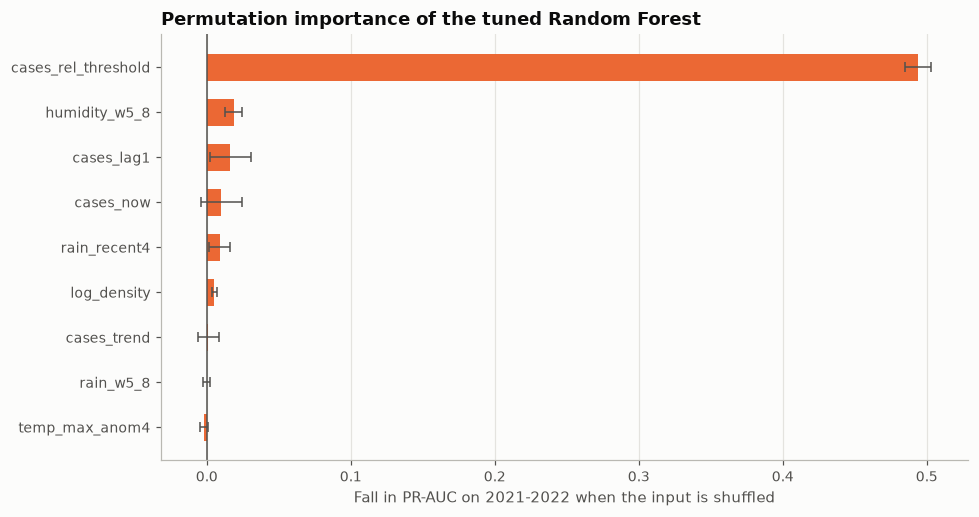

In [16]:
ordered = importance.sort_values("permutation: drop in PR-AUC")
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(ordered.index, ordered["permutation: drop in PR-AUC"], height=0.6, color=viz.ORANGE,
        xerr=ordered["permutation: std"], error_kw={"ecolor": viz.TEXT_MUTED, "elinewidth": 1, "capsize": 3})
ax.axvline(0, color=viz.TEXT_MUTED, linewidth=1)
ax.set_xlabel("Fall in PR-AUC on 2021-2022 when the input is shuffled")
ax.set_title("Permutation importance of the tuned Random Forest")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save(fig, "rf_04_feature_importance")
plt.show()

**Finding.** One input dominates. Shuffling `cases_rel_threshold` cuts PR-AUC by 0.494, and it accounts for 91% of the impurity importance. No other input changes PR-AUC by more than 0.02. Humidity five to eight weeks earlier (0.019), last week's cases (0.016), this week's cases (0.010) and recent rainfall (0.009) contribute a little, some of it within the noise of the shuffling, while `rain_w5_8`, `cases_trend` and the temperature anomaly add nothing measurable.

This explains why the forest tracks the persistence score so closely: it is, in effect, a refined version of that one ratio, adjusted slightly by recent history and humidity.

## 8. Summary for the report

- **Tuned settings:** 300 trees, maximum depth 6, at least 50 weeks per leaf, all 9 inputs considered at each split, no class weighting. Decision threshold 0.32, chosen on the cross-validation predictions.
- **Cross-validation, 2016 to 2020:** PR-AUC 0.711, ahead of the persistence score (0.687) in all five years and 0.045 above the untuned forest. Dropping class weighting gave most of the gain; restraining tree growth added a little more.
- **Where the gain comes from:** judging whether an ongoing outbreak will continue (PR-AUC 0.852 against 0.818). At onsets the forest is only level with the persistence score in cross-validation.
- **Validation, 2021 to 2022:** PR-AUC 0.538 against 0.554 for the persistence score, a gap well within bootstrap noise for a period with only 77 outbreak weeks. The forest catches 47 of the 77 outbreaks (persistence 43) with more false alarms (51 against 34), and ranks onsets better (0.140 against 0.082).
- **What the forest relies on:** `cases_rel_threshold` dominates; humidity and recent case history add a little; the other inputs add nothing measurable.

**Points for the critical analysis**

- At a two-week horizon most of the signal is the current case level relative to the district's threshold, so a well-chosen simple rule is hard to beat. The forest's margin is real in cross-validation but small.
- The best setting uses all 9 inputs at every split, which is bagging rather than a random forest in the strict sense. With few inputs and one dominant, random feature selection did not help.
- Two validation years with 77 outbreak weeks are too few to separate models whose PR-AUC differs by a few hundredths.

The tuned settings and threshold are saved to `results/metrics/rf_final_settings.json` for the final comparison in step 11.

In [17]:
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
tuning.to_csv(config.METRICS_DIR / "rf_tuning_results.csv", index=False)
by_year.to_csv(config.METRICS_DIR / "rf_cv_by_year.csv")
cv_metrics.to_csv(config.METRICS_DIR / "rf_cv_threshold_metrics.csv", index=False)
onsets.to_csv(config.METRICS_DIR / "rf_onsets.csv")
validation.to_csv(config.METRICS_DIR / "rf_validation_metrics.csv")
importance.to_csv(config.METRICS_DIR / "rf_feature_importance.csv")

final_settings = {
    "model": "Random Forest",
    "owner": "Member B",
    "preprocessing": "make_selected_preprocessor() (L1 selection, C = 0.01)",
    "hyperparameters": {"n_estimators": N_TREES, "random_state": config.RANDOM_SEED, **best_clf},
    "decision_threshold": round(THRESHOLD, 6),
    "threshold_rule": "maximise F1 averaged across the 2016-2020 cross-validation years",
    "cv_mean_pr_auc_2016_2020": round(float(search.best_score_), 6),
    "validation_pr_auc_2021_2022": round(float(validation.loc["Random Forest, tuned", "PR-AUC"]), 6),
    "inputs_used": inputs,
    "trained_on": "train split, 2007-2020",
}
with open(config.METRICS_DIR / "rf_final_settings.json", "w") as f:
    json.dump(final_settings, f, indent=2, default=str)
print("Saved rf_* tables and rf_final_settings.json to results/metrics/")
final_settings

Saved rf_* tables and rf_final_settings.json to results/metrics/


{'model': 'Random Forest',
 'owner': 'Member B',
 'preprocessing': 'make_selected_preprocessor() (L1 selection, C = 0.01)',
 'hyperparameters': {'n_estimators': 300,
  'random_state': 42,
  'class_weight': None,
  'max_depth': 6,
  'max_features': 1.0,
  'min_samples_leaf': 50},
 'decision_threshold': 0.322905,
 'threshold_rule': 'maximise F1 averaged across the 2016-2020 cross-validation years',
 'cv_mean_pr_auc_2016_2020': 0.711472,
 'validation_pr_auc_2021_2022': 0.538242,
 'inputs_used': ['cases_now',
  'cases_lag1',
  'cases_rel_threshold',
  'rain_recent4',
  'rain_w5_8',
  'cases_trend',
  'humidity_w5_8',
  'temp_max_anom4',
  'log_density'],
 'trained_on': 'train split, 2007-2020'}